## Project Overview

 This project focuses on performing Exploratory Data Analysis (EDA) on an online retail transaction dataset to uncover business insights, identify purchasing patterns, evaluate sales performance and understand customer behaviour.

The analysis uses Python to investigate transaction records, assess data quality, identify trends and visualize important business metrics.

Project Objectives

- Examine and understand the structure of the dataset.
- Identify and address data-quality issues.
- Analyse revenue and product performance.
- Investigate customer purchasing behaviour.
- Explore sales trends across time and geographical markets.
- Identify meaningful business insights and provide recommendations.

Dataset Description

The Online Retail dataset contains transactional records from a UK-based online retail business, covering transactions between December 2010 and December 2011.

Tools and Technologies

- Python
- Jupyter Notebook
- Pandas
- NumPy
- Matplotlib
- Seaborn

Expected Deliverables

A cleaned analytical dataset, exploratory visualizations, documented findings and actionable business recommendations.

## Import Libraries and Loading data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# read the excel file
customer_data = pd.read_excel('Online Retail.xlsx')
(customer_data)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France


## Perform Data Exploration

In [3]:
(customer_data.shape)       # (rows, columns)

(541909, 8)

In [4]:
(customer_data.info())      # column names, data types, nulls

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [5]:
(customer_data.head())    # first 5 rows

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


### Perform Data Quality Assessment

In [6]:
#check for duplicate
customer_data.duplicated().sum()

np.int64(5268)

In [7]:
#check for cancelled orders
#check the invoice column
customer_data['InvoiceNo'].head(20)

0     536365
1     536365
2     536365
3     536365
4     536365
5     536365
6     536365
7     536366
8     536366
9     536367
10    536367
11    536367
12    536367
13    536367
14    536367
15    536367
16    536367
17    536367
18    536367
19    536367
Name: InvoiceNo, dtype: object

In [8]:
#check for cancelled invoice
cancelled = customer_data[customer_data['InvoiceNo'].astype(str).str.startswith('C')]
cancelled.shape

(9288, 8)

In [9]:
# Highlight cancelled transactions
cancelled.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom


In [10]:
#Check negative Quantities
(customer_data['Quantity'] < 0).sum()

np.int64(10624)

In [11]:
customer_data[customer_data['Quantity'] < 0].head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897.0,United Kingdom


In [12]:
#Checking missing Customer IDs
customer_data['CustomerID'].isnull().sum()

np.int64(135080)

## Dataset Cleaning

In [13]:
# Preserve the original dataset
customer_data_clean = customer_data.copy()         # Create a cleaned working copy dataset for the analysis

print("Original dataset shape", customer_data.shape)
print("Working dataset shape", customer_data_clean.shape)                   

Original dataset shape (541909, 8)
Working dataset shape (541909, 8)


In [14]:
#Remove duplicate values
customer_data_clean = customer_data_clean.drop_duplicates()

In [15]:
customer_data_clean.duplicated().sum()

np.int64(0)

In [16]:
(customer_data_clean)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France


### Standardize text columns

In [17]:
# Remove unnecessary spaces from text fields

customer_data_clean["Description"] = customer_data_clean["Description"].str.strip()
customer_data_clean["Country"] = customer_data_clean["Country"].str.strip()

# Convert InvoiceDate to datetime
customer_data_clean["InvoiceDate"] = pd.to_datetime(
    customer_data_clean["InvoiceDate"],
    errors="coerce"
)

print("InvoiceDate data type:", customer_data_clean["InvoiceDate"].dtype)
print("Missing dates after conversion:", customer_data_clean["InvoiceDate"].isna().sum())


InvoiceDate data type: datetime64[ns]
Missing dates after conversion: 0


In [18]:
#Remove cancelled invoices               [invoices beginning with C are cancelled orders]
customer_data_clean = customer_data_clean[~customer_data_clean['InvoiceNo'].astype(str).str.startswith('C')]

In [19]:
customer_data_clean.shape

(527390, 8)

In [20]:
#Remove negative quantities              [Negative quantities represent returned/negative transactions]
customer_data_clean = customer_data_clean[customer_data_clean['Quantity'] > 0]

In [21]:
#Remove customers without an ID
customer_data_clean.dropna(subset=['CustomerID'])

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France


In [22]:
customer_data_clean.isnull().sum()

InvoiceNo           0
StockCode           0
Description       592
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     133322
Country             0
dtype: int64

In [23]:
#Convert InvoiceDate column to datetime(data_type)
customer_data_clean['InvoiceDate'] = pd.to_datetime(customer_data_clean['InvoiceDate'])

In [24]:
customer_data_clean['InvoiceDate'].dtype

dtype('<M8[ns]')

In [25]:
#checking the transaction date range
customer_data_clean['InvoiceDate'].min(),
customer_data_clean['InvoiceDate'].max()

Timestamp('2011-12-09 12:50:00')

In [26]:
customer_data_clean['InvoiceDate'].head(10)

0   2010-12-01 08:26:00
1   2010-12-01 08:26:00
2   2010-12-01 08:26:00
3   2010-12-01 08:26:00
4   2010-12-01 08:26:00
5   2010-12-01 08:26:00
6   2010-12-01 08:26:00
7   2010-12-01 08:28:00
8   2010-12-01 08:28:00
9   2010-12-01 08:34:00
Name: InvoiceDate, dtype: datetime64[ns]

In [27]:
customer_data_clean.shape

(526054, 8)

In [28]:
#Checking for missing date
customer_data_clean['InvoiceDate'].isna().sum()

np.int64(0)

### Perform Exploratory Data Analysis
#### Business Metrics

In [29]:
# create a new column
customer_data_clean['Revenue'] = (customer_data_clean['Quantity'] * customer_data_clean['UnitPrice'])

In [30]:
customer_data_clean[['Quantity','UnitPrice','Revenue']].head()

,Quantity,UnitPrice,Revenue
0,6,2.55,15.30
1,6,3.39,20.34
2,8,2.75,22.00
3,6,3.39,20.34
4,6,3.39,20.34


#### Calculate key business metrics

In [31]:
total_revenue = customer_data_clean["Revenue"].sum()
total_orders = customer_data_clean["InvoiceNo"].nunique()
total_customers = customer_data_clean["CustomerID"].nunique()
total_products = customer_data_clean["StockCode"].nunique()
total_units_sold = customer_data_clean["Quantity"].sum()

print("Total Revenue:", round(total_revenue, 2))
print("Total Orders:", total_orders)
print("Total Customers:", total_customers)
print("Total Products:", total_products)
print("Total Units Sold:", total_units_sold)


Total Revenue: 10619986.68
Total Orders: 20728
Total Customers: 4339
Total Products: 3941
Total Units Sold: 5645019


#### Calculate average order value

In [32]:
order_revenue = customer_data_clean.groupby("InvoiceNo")["Revenue"].sum()

average_order_value = order_revenue.mean()

print("Average Order Value:", round(average_order_value, 2))

Average Order Value: 512.35


#### Analyse revenue trend overtime

In [33]:
# Extract year and month from InvoiceDate
customer_data_clean["YearMonth"] = customer_data_clean["InvoiceDate"].dt.to_period("M")

# Group revenue by month
monthly_revenue = (
    customer_data_clean.groupby("YearMonth")["Revenue"]
    .sum()
    .reset_index()
)

monthly_revenue["YearMonth"] = (
    monthly_revenue["YearMonth"].astype(str)
)

display(monthly_revenue)

,YearMonth,Revenue
0,2010-12,821452.730
1,2011-01,689811.610
2,2011-02,522545.560
3,2011-03,716215.260
4,2011-04,536968.491
5,2011-05,769296.610
6,2011-06,760547.010
7,2011-07,718076.121
8,2011-08,735717.260
9,2011-09,1056435.192


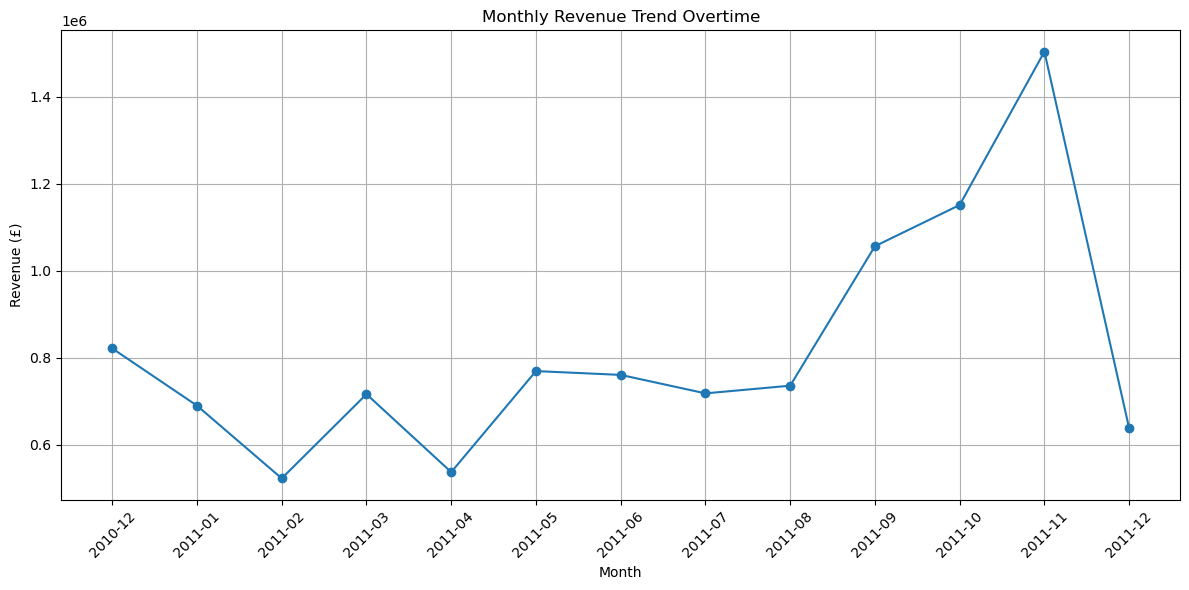

In [34]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_revenue["YearMonth"],
    monthly_revenue["Revenue"],
    marker="o"
)

plt.title("Monthly Revenue Trend Overtime")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()


### Analyse the best-selling products

In [35]:
# Question 1) Top 10 products by revenue

top_products_revenue = (
    customer_data_clean.groupby("Description")
    .agg(
       Total_Revenue=("Revenue","sum"),
       Units_Sold=("Quantity","sum"))
    .sort_values("Total_Revenue", ascending=False)
    .head(10)
    .reset_index()
)

display(top_products_revenue)

,Description,Total_Revenue,Units_Sold
0,DOTCOM POSTAGE,206248.77,708
1,REGENCY CAKESTAND 3 TIER,174156.54,13862
2,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995
3,WHITE HANGING HEART T-LIGHT HOLDER,106236.72,37876
4,PARTY BUNTING,99445.23,18287
5,JUMBO BAG RED RETROSPOT,94159.81,48375
6,MEDIUM CERAMIC TOP STORAGE JAR,81700.92,78033
7,POSTAGE,78101.88,3150
8,Manual,77752.82,6991
9,RABBIT NIGHT LIGHT,66870.03,30739


In [36]:
# Question 2) Identify the top 10 products by quantity sold

top_products_quantity = (
    customer_data_clean.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

top_products_quantity.columns = [
    "Product",
    "Total_Quantity_Sold"
]

display(top_products_quantity)


,Product,Total_Quantity_Sold
0,"PAPER CRAFT , LITTLE BIRDIE",80995
1,MEDIUM CERAMIC TOP STORAGE JAR,78033
2,WORLD WAR 2 GLIDERS ASSTD DESIGNS,54951
3,JUMBO BAG RED RETROSPOT,48375
4,WHITE HANGING HEART T-LIGHT HOLDER,37876
5,POPCORN HOLDER,36749
6,PACK OF 72 RETROSPOT CAKE CASES,36396
7,ASSORTED COLOUR BIRD ORNAMENT,36362
8,RABBIT NIGHT LIGHT,30739
9,MINI PAINT SET VINTAGE,26633


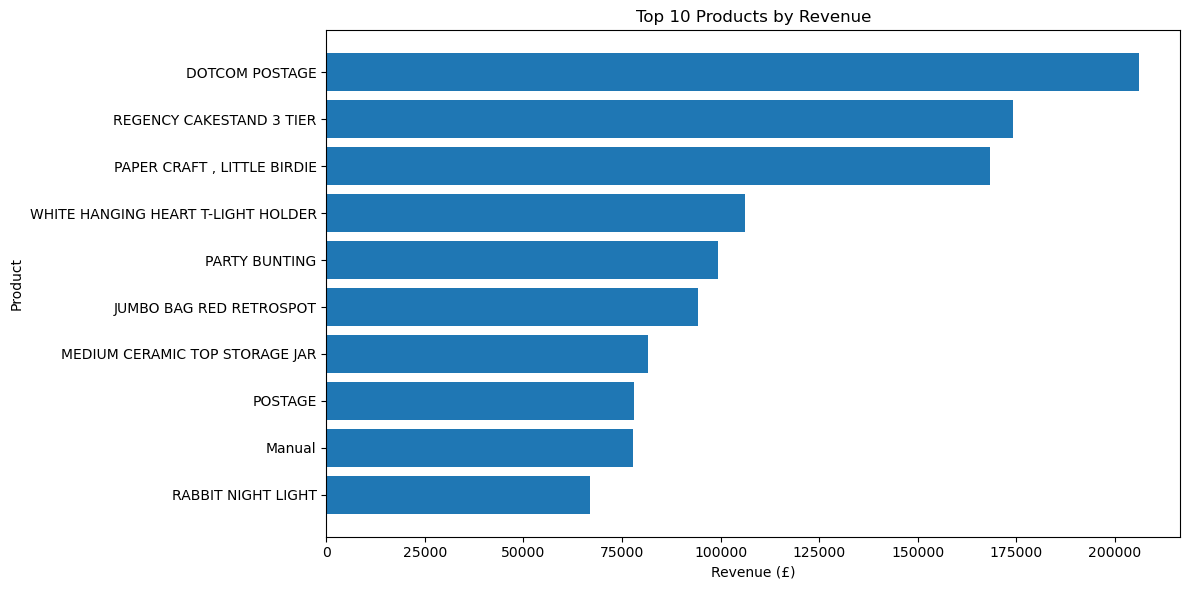

In [37]:
plt.figure(figsize=(12, 6))

plt.barh(
    top_products_revenue["Description"],
    top_products_revenue["Total_Revenue"]
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Product")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

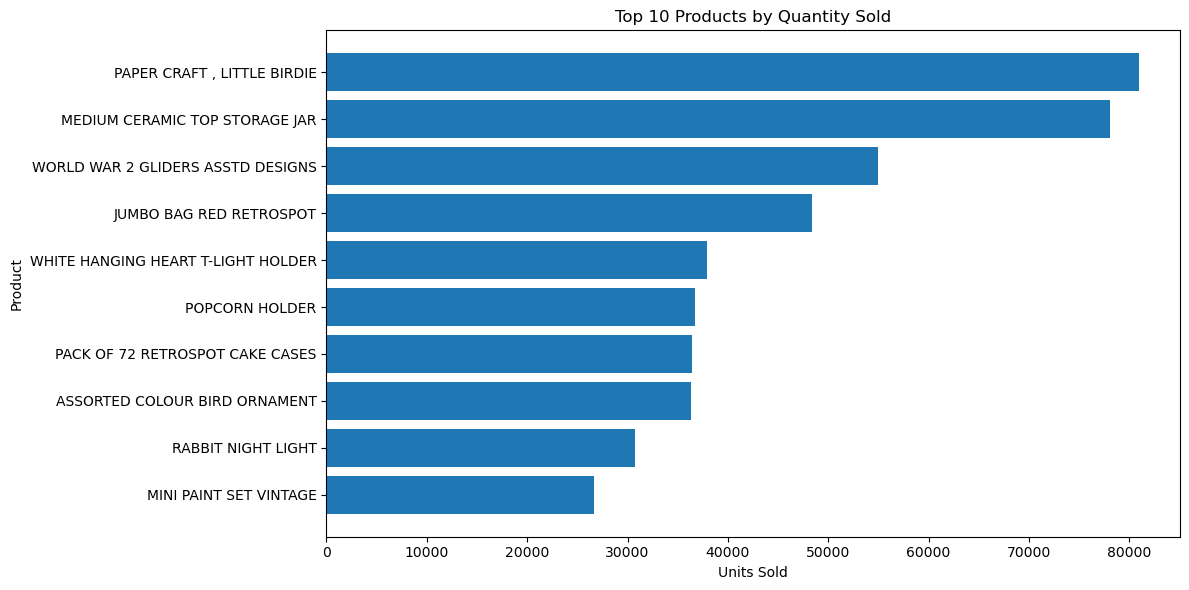

In [38]:
plt.figure(figsize=(12, 6))

plt.barh(
    top_products_quantity["Product"],
    top_products_quantity["Total_Quantity_Sold"]
)

plt.title("Top 10 Products by Quantity Sold")
plt.xlabel("Units Sold")
plt.ylabel("Product")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

### Analyse sales performance by country

In [39]:
country_analysis = (
    customer_data_clean.groupby("Country")
    .agg(
        Total_Revenue=("Revenue", "sum"),
        Total_Orders=("InvoiceNo", "nunique"),
        Total_Customers=("CustomerID", "nunique"),
        Units_Sold=("Quantity", "sum")
    )
    .sort_values("Total_Revenue", ascending=False)
    .reset_index()
)

display(country_analysis.head(15))

,Country,Total_Revenue,Total_Orders,Total_Customers,Units_Sold
0,United Kingdom,8979619.974,18786,3921,4718329
1,Netherlands,285446.340,95,9,200937
2,EIRE,283140.520,288,3,147281
3,Germany,228678.400,457,94,119156
4,France,209625.370,392,87,112061
5,Australia,138453.810,57,9,84199
6,Spain,61558.560,90,30,27944
7,Switzerland,57067.600,54,21,30618
8,Belgium,41196.340,98,25,23237
9,Sweden,38367.830,36,8,36078


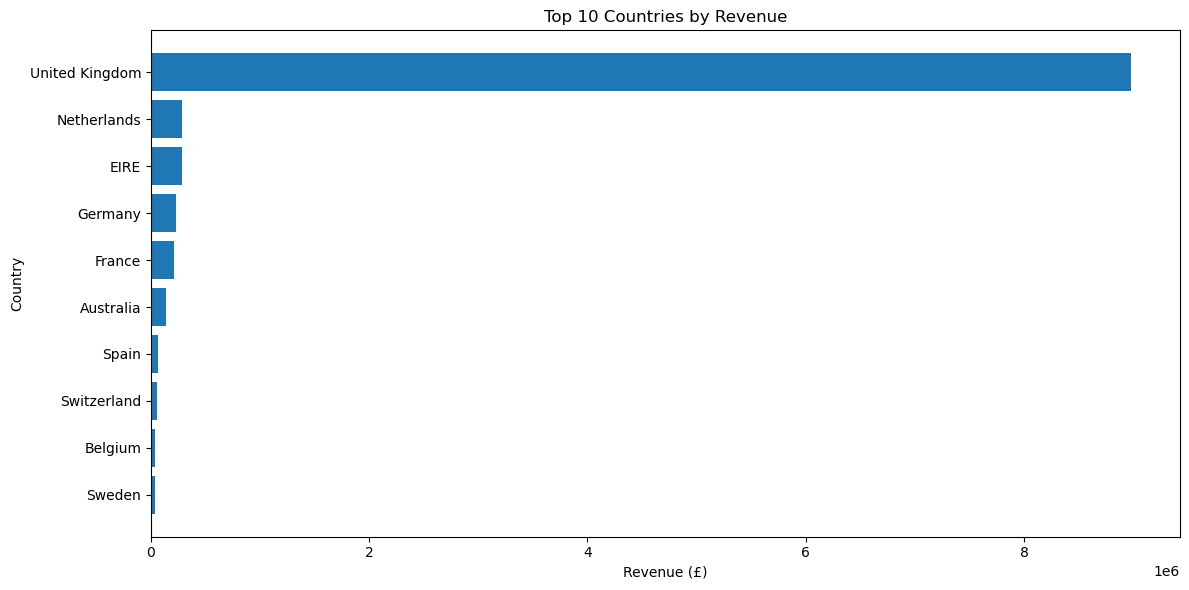

In [40]:
top_countries = country_analysis.head(10)

plt.figure(figsize=(12, 6))

plt.barh(
    top_countries["Country"],
    top_countries["Total_Revenue"]
)

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Country")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

### Analyse customer purchasing behaviour

Business questions:
Who are the highest-spending customers?
How many orders does each customer place?
How much revenue does the average customer generate?
Does the business depend heavily on a small number of customers?

In [41]:
# calculate customer metrics
customer_analysis = (
    customer_data_clean.dropna(subset=["CustomerID"])
    .groupby("CustomerID")
    .agg(
        Total_Spending=("Revenue", "sum"),
        Total_Orders=("InvoiceNo", "nunique"),
        Total_Quantity=("Quantity", "sum"),
        First_Purchase=("InvoiceDate", "min"),
        Last_Purchase=("InvoiceDate", "max")
    )
    .reset_index()
)

display(customer_analysis.head())


,CustomerID,Total_Spending,Total_Orders,Total_Quantity,First_Purchase,Last_Purchase
0,12346.0,77183.60,1,74215,2011-01-18 10:01:00,2011-01-18 10:01:00
1,12347.0,4310.00,7,2458,2010-12-07 14:57:00,2011-12-07 15:52:00
2,12348.0,1797.24,4,2341,2010-12-16 19:09:00,2011-09-25 13:13:00
3,12349.0,1757.55,1,631,2011-11-21 09:51:00,2011-11-21 09:51:00
4,12350.0,334.40,1,197,2011-02-02 16:01:00,2011-02-02 16:01:00


In [42]:
# identify top 10 highest-spending customers
top_customers = customer_analysis.sort_values(
    by="Total_Spending",
    ascending=False
).head(10)

display(top_customers)


,CustomerID,Total_Spending,Total_Orders,Total_Quantity,First_Purchase,Last_Purchase
1690,14646.0,280206.02,74,197491,2010-12-20 10:09:00,2011-12-08 12:12:00
4202,18102.0,259657.30,60,64124,2010-12-07 16:42:00,2011-12-09 11:50:00
3729,17450.0,194390.79,46,69973,2010-12-07 09:23:00,2011-12-01 13:29:00
3009,16446.0,168472.50,2,80997,2011-05-18 09:52:00,2011-12-09 09:15:00
1880,14911.0,143711.17,201,80490,2010-12-01 14:05:00,2011-12-08 15:54:00
55,12415.0,124914.53,21,77670,2011-01-06 11:12:00,2011-11-15 14:22:00
1334,14156.0,117210.08,55,57768,2010-12-03 11:48:00,2011-11-30 10:54:00
3772,17511.0,91062.38,31,64549,2010-12-01 10:19:00,2011-12-07 10:12:00
2703,16029.0,80850.84,63,40108,2010-12-01 09:57:00,2011-11-01 10:27:00
0,12346.0,77183.60,1,74215,2011-01-18 10:01:00,2011-01-18 10:01:00


In [43]:
# Calculate overall customer metrics
print("Total Customers:", customer_analysis["CustomerID"].nunique())

print(
    "Average Customer Spending (£):",
    round(customer_analysis["Total_Spending"].mean(), 2)
)

print(
    "Average Orders per Customer:",
    round(customer_analysis["Total_Orders"].mean(), 2)
)

print(
    "Highest Customer Spending (£):",
    round(customer_analysis["Total_Spending"].max(), 2)
)

Total Customers: 4339
Average Customer Spending (£): 2048.22
Average Orders per Customer: 4.27
Highest Customer Spending (£): 280206.02


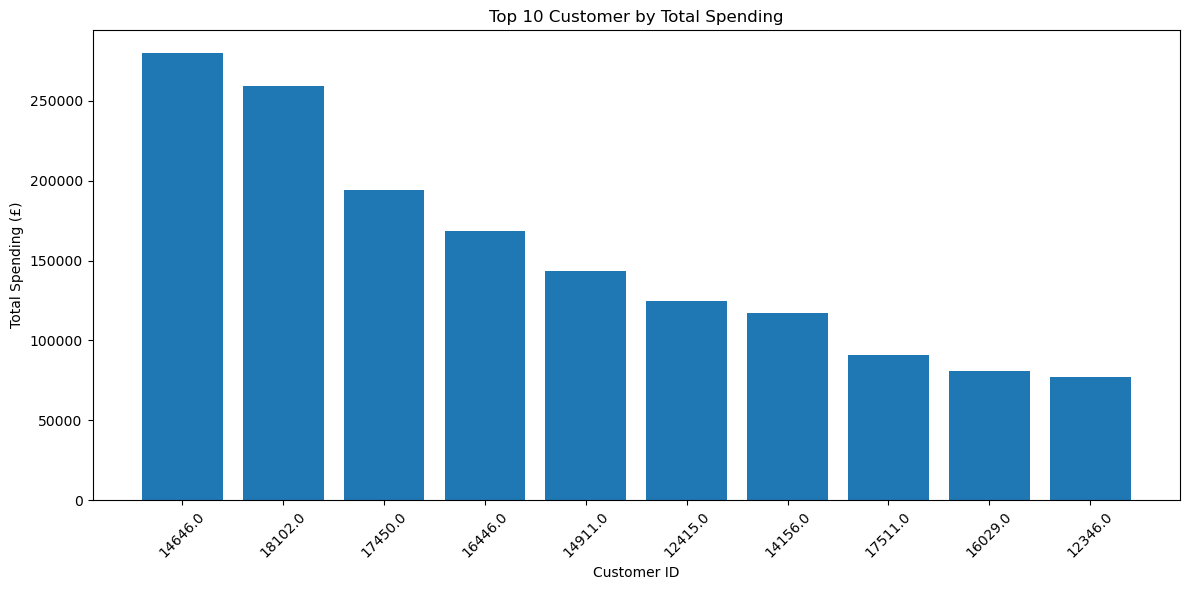

In [44]:
# visualize the top 10 customers
plt.figure(figsize=(12, 6))

plt.bar(
    top_customers["CustomerID"].astype(str),
    top_customers["Total_Spending"]
)

plt.title("Top 10 Customer by Total Spending")
plt.xlabel("Customer ID")
plt.ylabel("Total Spending (£)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## Analyse Repeat Customers and Purchasing Frequency
Business questions: How many customers made only one purchase and multiple purchases?
                    What percentage of customers are repeat customers?
                    How much revenue comes from repeat customers?
#### Categorize customers by purchasing frequency

In [45]:
# Classify customers based on number of orders
customer_analysis["Customer_Type"] = customer_analysis[
    "Total_Orders"
].apply(
    lambda x: "Repeat Customer" if x > 1 else "One-time Customer"
)

display(customer_analysis.head(10))

,CustomerID,Total_Spending,Total_Orders,Total_Quantity,First_Purchase,Last_Purchase,Customer_Type
0,12346.0,77183.60,1,74215,2011-01-18 10:01:00,2011-01-18 10:01:00,One-time Customer
1,12347.0,4310.00,7,2458,2010-12-07 14:57:00,2011-12-07 15:52:00,Repeat Customer
2,12348.0,1797.24,4,2341,2010-12-16 19:09:00,2011-09-25 13:13:00,Repeat Customer
3,12349.0,1757.55,1,631,2011-11-21 09:51:00,2011-11-21 09:51:00,One-time Customer
4,12350.0,334.40,1,197,2011-02-02 16:01:00,2011-02-02 16:01:00,One-time Customer
5,12352.0,2506.04,8,536,2011-02-16 12:33:00,2011-11-03 14:37:00,Repeat Customer
6,12353.0,89.00,1,20,2011-05-19 17:47:00,2011-05-19 17:47:00,One-time Customer
7,12354.0,1079.40,1,530,2011-04-21 13:11:00,2011-04-21 13:11:00,One-time Customer
8,12355.0,459.40,1,240,2011-05-09 13:49:00,2011-05-09 13:49:00,One-time Customer
9,12356.0,2811.43,3,1591,2011-01-18 09:50:00,2011-11-17 08:40:00,Repeat Customer


#### Count one-time and repeat customers

In [46]:
customer_types = customer_analysis[
    "Customer_Type"
].value_counts()

display(customer_types)

Customer_Type
Repeat Customer      2845
One-time Customer    1494
Name: count, dtype: int64

#### Calculate repeat customer percentage

In [47]:
total_customers = len(customer_analysis)

repeat_customers = (
    customer_analysis["Customer_Type"] == "Repeat Customer"
).sum()

one_time_customers = (
    customer_analysis["Customer_Type"] == "One-time Customer"
).sum()

repeat_percentage = (
    repeat_customers / total_customers
) * 100

print("Total Customers:", total_customers)
print("Repeat Customers:", repeat_customers)
print("One-time Customers:", one_time_customers)
print("Repeat Customer Percentage:", round(repeat_percentage, 2), "%")

Total Customers: 4339
Repeat Customers: 2845
One-time Customers: 1494
Repeat Customer Percentage: 65.57 %


#### Compare revenue from both customer groups

In [48]:
customer_revenue = (
    customer_analysis.groupby("Customer_Type")["Total_Spending"]
    .sum()
    .reset_index()
)

display(customer_revenue)

,Customer_Type,Total_Spending
0,One-time Customer,613989.561
1,Repeat Customer,8273219.333


#### Visualize customer distribution

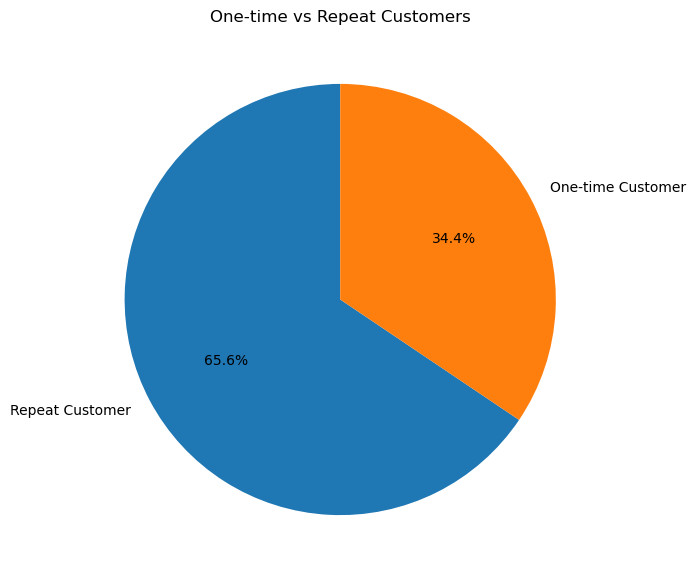

In [49]:
plt.figure(figsize=(7, 7))

plt.pie(
    customer_types,
    labels=customer_types.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("One-time vs Repeat Customers")
plt.show()

### Analyse relationship between variables (Correlation Analysis)

Business questions: 1) Does selling more units generally generate more revenue?

                2) Is unit price strongly related to revenue?

                3) How do quantity and unit price relate to each other?

In [50]:
# Select numerical variables
correlation_data = customer_data_clean[
    ["Quantity", "UnitPrice", "Revenue"]
]

# Calculate correlation matrix
correlation_matrix=correlation_data.corr()

# Display results
display(correlation_matrix)

,Quantity,UnitPrice,Revenue
Quantity,1.000000,-0.003226,0.895957
UnitPrice,-0.003226,1.000000,0.158283
Revenue,0.895957,0.158283,1.000000


#### Visualize the correlation matrix

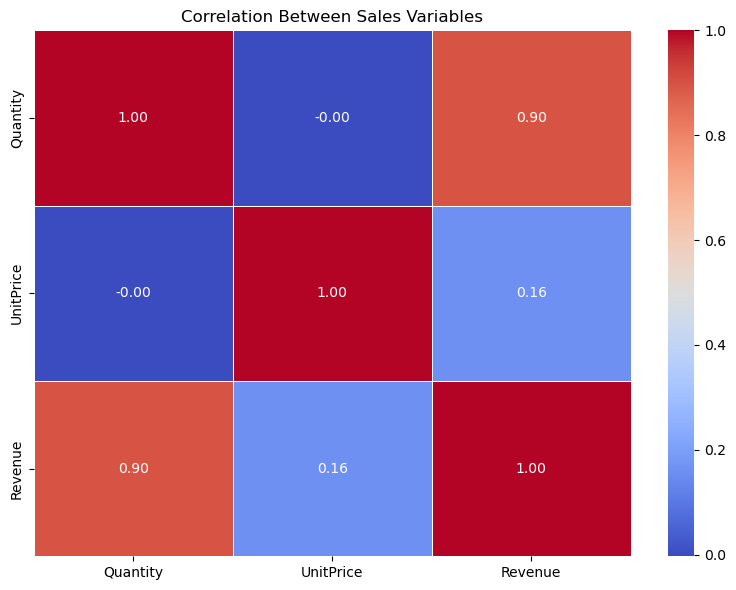

In [51]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Between Sales Variables")
plt.tight_layout()
plt.show()

## Key Business Summary

In [52]:
print("========== EDA KEY FINDINGS ==========")

print("\n1. SALES PERFORMANCE")
print("Total Revenue (£):", round(customer_data_clean["Revenue"].sum(), 2))
print("Total Orders:", customer_data_clean["InvoiceNo"].nunique())

print("\n2. PRODUCT PERFORMANCE")
display(top_products_revenue.head(5))

print("\n3. COUNTRY PERFORMANCE")
display(country_analysis.head(5))

print("\n4. CUSTOMER PERFORMANCE")
display(top_customers.head(5))

print("\n5. MONTHLY SALES PERFORMANCE")
display(monthly_revenue)

print("\n6. CUSTOMER RETENTION")
display(customer_types)

========== EDA KEY FINDINGS ==========

1. SALES PERFORMANCE
Total Revenue (£): 10619986.68
Total Orders: 20728

2. PRODUCT PERFORMANCE


,Description,Total_Revenue,Units_Sold
0,DOTCOM POSTAGE,206248.77,708
1,REGENCY CAKESTAND 3 TIER,174156.54,13862
2,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995
3,WHITE HANGING HEART T-LIGHT HOLDER,106236.72,37876
4,PARTY BUNTING,99445.23,18287



3. COUNTRY PERFORMANCE


,Country,Total_Revenue,Total_Orders,Total_Customers,Units_Sold
0,United Kingdom,8979619.974,18786,3921,4718329
1,Netherlands,285446.340,95,9,200937
2,EIRE,283140.520,288,3,147281
3,Germany,228678.400,457,94,119156
4,France,209625.370,392,87,112061



4. CUSTOMER PERFORMANCE


,CustomerID,Total_Spending,Total_Orders,Total_Quantity,First_Purchase,Last_Purchase
1690,14646.0,280206.02,74,197491,2010-12-20 10:09:00,2011-12-08 12:12:00
4202,18102.0,259657.30,60,64124,2010-12-07 16:42:00,2011-12-09 11:50:00
3729,17450.0,194390.79,46,69973,2010-12-07 09:23:00,2011-12-01 13:29:00
3009,16446.0,168472.50,2,80997,2011-05-18 09:52:00,2011-12-09 09:15:00
1880,14911.0,143711.17,201,80490,2010-12-01 14:05:00,2011-12-08 15:54:00



5. MONTHLY SALES PERFORMANCE


,YearMonth,Revenue
0,2010-12,821452.730
1,2011-01,689811.610
2,2011-02,522545.560
3,2011-03,716215.260
4,2011-04,536968.491
5,2011-05,769296.610
6,2011-06,760547.010
7,2011-07,718076.121
8,2011-08,735717.260
9,2011-09,1056435.192



6. CUSTOMER RETENTION


Customer_Type
Repeat Customer      2845
One-time Customer    1494
Name: count, dtype: int64

In [53]:
print(
    customer_data_clean.groupby("Country")["CustomerID"]
    .agg(
        Missing_IDs=lambda x: x.isna().sum(),
        Unique_Customers="nunique"
    )
    .sort_values("Unique_Customers")
    .head(10)
)

                    Missing_IDs  Unique_Customers
Country                                          
Hong Kong                   280                 0
Brazil                        0                 1
Singapore                     0                 1
Saudi Arabia                  0                 1
RSA                           0                 1
Czech Republic                0                 1
European Community            0                 1
Lithuania                     0                 1
Lebanon                       0                 1
Iceland                       0                 1


## KEY FINDINGS AND BUSINESS INSIGHTS

1. Sales Performance

The analysis recorded approximately £10.62 million in revenue across 20,728 orders. This indicates substantial transaction activity throughout the dataset's observation period.

2. Product Performance

DOTCOM POSTAGE generated the highest recorded revenue among the product descriptions. Regency Cake Stand 3 Tier and Paper Craft, Little Birdie were also significant revenue contributors.

Postage charges should be considered separately from physical merchandise when evaluating product performance.

3. Geographic Performance

The United Kingdom was the dominant revenue-generating market, contributing approximately £8.98 million. Other notable markets included the Netherlands, EIRE, Germany and France.

4. Customer Behaviour

The customer analysis identified 4,339 customers. Of these, 2,845 were repeat customers, while 1,494 made only one recorded purchase. This represents an approximate repeat customer rate of 65.57%.

5. Monthly Sales Trends

November 2011 recorded the highest monthly revenue at approximately £1.50 million, while February 2011 recorded the lowest at approximately £522,546.

The results indicate stronger revenue performance towards the final quarter of 2011. December 2011 requires caution because the dataset contains only part of that month.

    RECOMMENDATIONS

1. Strengthen customer retention through loyalty programmes and targeted promotions.
2. Prioritise inventory planning for high-performing merchandise.
3. Investigate opportunities to expand sales in international markets.
4. Prepare inventory and marketing campaigns ahead of historically strong sales periods.
5. Monitor customer data completeness to improve customer-level reporting.


CONCLUSION

This Exploratory Data Analysis project examined the Online Retail dataset to understand the business's sales performance, product demand, geographical markets and customer purchasing behaviour.

Using Python, Pandas, Matplotlib and Seaborn, the analysis involved data inspection, data cleaning, statistical exploration and visualization to identify meaningful patterns and business insights.

The analysis revealed that the retailer generated approximately £10.62 million in revenue from 20,728 unique orders. The United Kingdom accounted for the largest share of revenue, while November 2011 recorded the highest monthly revenue during the period examined.

Product analysis identified DOTCOM POSTAGE as the highest revenue-generating description, while customer analysis showed that approximately 65.57% of identified customers made repeat purchases. These findings provide useful insights into the retailer's revenue distribution, product performance and customer purchasing behaviour.

The analysis also identified data-quality limitations, particularly missing customer identification records, cancelled transactions and unusual transaction values. These issues were considered during data preparation to ensure that the sales analysis was based on appropriate transaction records.

Based on the findings, the business could improve customer retention through targeted loyalty initiatives, strengthen inventory planning around high-demand products and periods, explore opportunities in international markets, and improve customer data collection.

Overall, this project demonstrates how Exploratory Data Analysis can transform raw transactional data into actionable business insights and support evidence-based decision-making.
